# 07 · SamplerV2 ile aktarım ve eşik denemesi

**Amaç:** Yeni primitive sonuç yapısına geçişi ve simülasyon/donanım olasılıklarının karşılaştırılmasını incelemek.

**Okuma notu:** Qiskit 2 ortamı gerekir. Donanımda 8 test örneği kullanılır. Eşik bu örneklerin etiketleriyle seçildiği için ayarlanmış sonuç keşif amaçlıdır. Simülatör örneklemesi tüm çağrılarda seed ile sabitlenmez.

**Durum:** Staj çalışması arşivi. Aşağıdaki çıktılar ZIP içinde kayıtlı geçmiş çalıştırmalara aittir; bu yayına hazırlık sırasında üretilmiş yeni deney sonuçları değildir. Deney kodu ve eski açıklamalar gelişim sürecini göstermek için korunmuştur; yöntem düzeltmeleri ve sınırlılıklar için [çalışma rehberini](../../docs/CALISMA_REHBERI.md), [sonuçları](../../docs/SONUCLAR.md) ve [yöntem incelemesini](../../docs/YONTEM_VE_SINIRLAR.md) okuyun.

**English:** Historical internship experiment. See the [English overview](../../README_EN.md). Saved outputs are historical evidence, not a fresh reproducibility claim.


# Bu Denemede Iris veri seti üzerinde hibrit bir sınıflandırma yapılmak hedeflenmiştir.

Qiskit Aer ve IBM Bilgisayarı kullanılarak daha önce oluşturulan kod fine-tune edilmeye çalışılmıştır.

İlk iş olarak SamplerV2 kullanabilmek için versiyon güncellemeleri yapılmıştır.


In [1]:
import qiskit_ibm_runtime, qiskit_aer
print("Runtime:", qiskit_ibm_runtime.__version__)
print("Aer:", qiskit_aer.__version__)


Runtime: 0.41.1
Aer: 0.17.1


In [2]:
import sklearn, qiskit, qiskit_aer, qiskit_ibm_runtime, numpy as np, matplotlib

print("scikit-learn:", sklearn.__version__)
print("Qiskit:", qiskit.__version__)
print("Aer:", qiskit_aer.__version__)
print("Runtime:", qiskit_ibm_runtime.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)


scikit-learn: 1.7.1
Qiskit: 2.1.2
Aer: 0.17.1
Runtime: 0.41.1
NumPy: 2.1.3
Matplotlib: 3.10.5


IBM donanımına erişim artık Qiskit Runtime ile ve SamplerV2 / EstimatorV2 primitifleri üzerinden yapılıyor.


### 🔑 IBM Quantum Hesap Bağlantısı (IBM Cloud Üzerinden)

1. **API Key Oluştur**  
   - IBM Cloud > IAM > API Keys > “Create API Key”  

2. **Instance Yarat**  
   - IBM Quantum Platform > Service Instance oluştur  
   - Instance detaylarından **CRN** değerini kopyala  

3. **Hesabı Kaydet**   
   Terminal’de şu komutu çalıştır:  

   ```bash
   python - <<'PY'
   from qiskit_ibm_runtime import QiskitRuntimeService
   QiskitRuntimeService.save_account(
       channel="ibm_cloud",
       token="BURAYA_API_KEY",
       instance="BURAYA_INSTANCE_CRN",
       overwrite=True
   )
   print("✅ IBM Cloud hesabı kaydedildi.")
   PY
  

Bu işlemin sonunda artık IBM Quantum cihazlarına bağlanabilir, devrelerini gerçek donanımda çalıştırabilirsin.


In [3]:
# IBM Quantum'a Bağlanma

from qiskit_ibm_runtime import QiskitRuntimeService

# CRN: IBM Cloud'da oluşturduğun instance'ın CRN değeri
INSTANCE = "YOUR_INSTANCE_CRN"

service = QiskitRuntimeService(channel="ibm_cloud", instance=INSTANCE)

# Backend seçimi (ör: ibm_brisbane)
backend = service.backend("ibm_brisbane")
print("Backend:", backend.name, "| Qubit:", backend.num_qubits)


Backend: ibm_brisbane | Qubit: 127


In [4]:
# Veri seti hazırlanması

from sklearn import datasets, model_selection
from sklearn.preprocessing import MinMaxScaler

# Iris (Setosa=0, Versicolor=1 → ilk 100 kayıt)
iris = datasets.load_iris()
X, Y = iris.data[:100], iris.target[:100]

X_train, X_test, Y_train, Y_test = model_selection.train_test_split(
    X, Y, test_size=0.33, random_state=42, stratify=Y
)

# [0, π] ölçekle → RX için uygun
scaler = MinMaxScaler(feature_range=(0, np.pi))
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

print("Train shape:", X_train_s.shape)


Train shape: (67, 4)


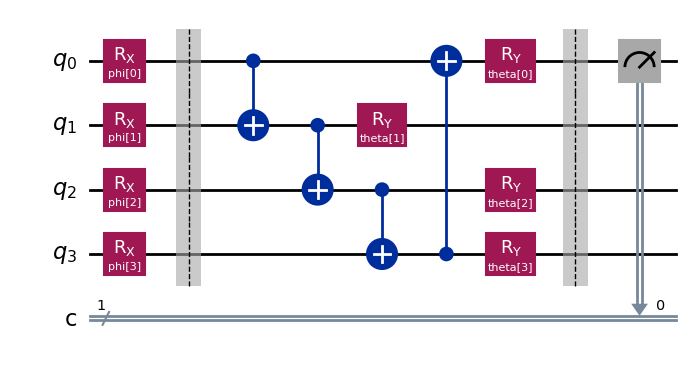

In [5]:
# Devre Tanıtımı

from qiskit.circuit import QuantumCircuit, QuantumRegister, ClassicalRegister, ParameterVector

N = 4
phi   = ParameterVector("phi", N)   # data
theta = ParameterVector("theta", N) # weights

def feature_map(phi):
    q = QuantumRegister(N, "q")
    c = ClassicalRegister(1, "c")
    qc = QuantumCircuit(q, c)
    for i in range(N):
        qc.rx(phi[i], q[i])
    return qc, c

def variational_layer(qc, theta):
    for i in range(N-1):
        qc.cx(i, i+1)
    qc.cx(N-1, 0)
    for i in range(N):
        qc.ry(theta[i], i)
    return qc

qc, c = feature_map(phi)
qc.barrier()
qc = variational_layer(qc, theta)
qc.barrier()
qc.measure(0, c[0])
qc.draw("mpl")


In [6]:
# Simülsyon için transpile

from qiskit_aer import AerSimulator
from qiskit import transpile

backend_sim = AerSimulator()
tqc_sim = transpile(qc, backend=backend_sim, optimization_level=1)

print("Devre depth:", tqc_sim.depth())


Devre depth: 7


In [7]:
# Simülasyon Fonksiyonları

def quantum_nn_sim(x_vals, theta_vals, shots=1024):
    bind = {phi[i]: float(x_vals[i]) for i in range(N)}
    bind |= {theta[j]: float(theta_vals[j]) for j in range(N)}
    circ = tqc_sim.assign_parameters(bind)
    job = backend_sim.run(circ, shots=shots)
    counts = job.result().get_counts()
    total = sum(counts.values())
    return counts.get("1", 0) / total

def accuracy_sim(X, Y, theta_vals, shots=1024, threshold=0.5):
    preds = []
    for x in X:
        p1 = quantum_nn_sim(x, theta_vals, shots=shots)
        preds.append(int(p1 >= threshold))
    return (np.array(preds) == np.array(Y)).mean()


In [8]:
# Simülasyonda eğitim

def train_qnn(X_train, Y_train, X_test, Y_test,
              epochs=10, eta=0.05, delta=1e-2):
    theta_vals = np.random.rand(N) * np.pi
    history = []

    for epoch in range(epochs):
        for x, y in zip(X_train, Y_train):
            # Gradient approx (finite-diff)
            g = np.zeros_like(theta_vals)
            for i in range(len(theta_vals)):
                thp = theta_vals.copy(); thp[i]+=delta
                thm = theta_vals.copy(); thm[i]-=delta
                lp = (quantum_nn_sim(x, thp)-y)**2
                lm = (quantum_nn_sim(x, thm)-y)**2
                g[i] = (lp-lm)/(2*delta)
            theta_vals -= eta * g

        acc_tr = accuracy_sim(X_train, Y_train, theta_vals)
        acc_te = accuracy_sim(X_test,  Y_test,  theta_vals)
        print(f"Epoch {epoch:02d} | train={acc_tr:.3f} | test={acc_te:.3f}")
        history.append((acc_tr, acc_te))
    return theta_vals, history

optimal_theta, hist = train_qnn(X_train_s, Y_train, X_test_s, Y_test, epochs=10)


Epoch 00 | train=0.388 | test=0.455
Epoch 01 | train=0.791 | test=0.788
Epoch 02 | train=0.806 | test=0.818
Epoch 03 | train=0.821 | test=0.788
Epoch 04 | train=0.806 | test=0.758
Epoch 05 | train=0.821 | test=0.758
Epoch 06 | train=0.836 | test=0.727
Epoch 07 | train=0.821 | test=0.818
Epoch 08 | train=0.806 | test=0.788
Epoch 09 | train=0.791 | test=0.818


In [9]:
from qiskit import transpile

def make_circuits_hw(X_batch, theta_vals, backend):
    circs = []
    for x in X_batch:
        bind = {phi[i]: float(x[i]) for i in range(N)}
        bind |= {theta[j]: float(theta_vals[j]) for j in range(N)}
        circ = qc.assign_parameters(bind)
        # Donanıma uygun kapılara çevir
        tqc = transpile(circ, backend=backend, optimization_level=3)
        circs.append(tqc)
    return circs

# Test subset
X_batch = X_test_s[:8]
circuits = make_circuits_hw(X_batch, optimal_theta, backend)

print("Hazırlanan transpile edilmiş devre sayısı:", len(circuits))


Hazırlanan transpile edilmiş devre sayısı: 8


In [11]:
from qiskit_ibm_runtime import SamplerV2
sampler = SamplerV2(backend)
job = sampler.run(circuits, shots=1024)
res = job.result()


In [13]:

# Sonuçları çıkar
predictions_hw = []
for i, pub_result in enumerate(res):
    counts = pub_result.data.c.get_counts()  # 'c' classical register adı
    total_shots = sum(counts.values())
    prob_1 = counts.get('1', 0) / total_shots  # '1' sonucu olasılığı
    predictions_hw.append(prob_1)
    print(f"Circuit {i}: P(1) = {prob_1:.3f}")

Circuit 0: P(1) = 0.579
Circuit 1: P(1) = 0.605
Circuit 2: P(1) = 0.465
Circuit 3: P(1) = 0.533
Circuit 4: P(1) = 0.414
Circuit 5: P(1) = 0.113
Circuit 6: P(1) = 0.263
Circuit 7: P(1) = 0.418


In [14]:
def extract_p1_hw(result):
    """SamplerV2 result → p(1) listesi"""
    p1_list = []
    for pub in result:
        counts = pub.data.c.get_counts()   # 'c' classical register
        total = sum(counts.values())
        p1 = counts.get('1', 0) / total if total > 0 else 0.0
        p1_list.append(p1)
    return p1_list

# Çalıştır
p1_hw = extract_p1_hw(res)
print("Hardware p(1):", [round(p,3) for p in p1_hw])


Hardware p(1): [0.579, 0.605, 0.465, 0.533, 0.414, 0.113, 0.263, 0.418]


In [15]:
import numpy as np

def hardware_accuracy(Y_true, predictions, threshold=0.5):
    preds = (np.array(predictions) >= threshold).astype(int)
    acc = (preds == np.array(Y_true)).mean()
    return acc, preds

Y_batch = Y_test[:len(p1_hw)]
acc_hw, preds_hw = hardware_accuracy(Y_batch, p1_hw, threshold=0.5)
print(f"Hardware Accuracy (thr=0.5): {acc_hw:.3f}")


Hardware Accuracy (thr=0.5): 0.625


In [16]:
def best_threshold(p1, y_true, grid=np.linspace(0.3, 0.7, 21)):
    best = (0, -1.0)
    for t in grid:
        preds = (np.array(p1) >= t).astype(int)
        acc = (preds == y_true).mean()
        if acc > best[1]:
            best = (t, acc)
    return best

t_opt, acc_opt = best_threshold(p1_hw, Y_batch)
print(f"Optimal threshold: {t_opt:.2f} → Accuracy: {acc_opt:.3f}")


Optimal threshold: 0.42 → Accuracy: 0.750


In [17]:
predictions_sim = [quantum_nn_sim(x, optimal_theta, shots=1024) for x in X_batch]

print("\nHardware vs Simulation:")
for i, (h, s) in enumerate(zip(p1_hw, predictions_sim)):
    print(f"Sample {i}: HW={h:.3f} | SIM={s:.3f} | Diff={abs(h-s):.3f}")



Hardware vs Simulation:
Sample 0: HW=0.579 | SIM=0.615 | Diff=0.036
Sample 1: HW=0.605 | SIM=0.613 | Diff=0.008
Sample 2: HW=0.465 | SIM=0.446 | Diff=0.019
Sample 3: HW=0.533 | SIM=0.514 | Diff=0.020
Sample 4: HW=0.414 | SIM=0.391 | Diff=0.023
Sample 5: HW=0.113 | SIM=0.085 | Diff=0.028
Sample 6: HW=0.263 | SIM=0.250 | Diff=0.013
Sample 7: HW=0.418 | SIM=0.395 | Diff=0.023


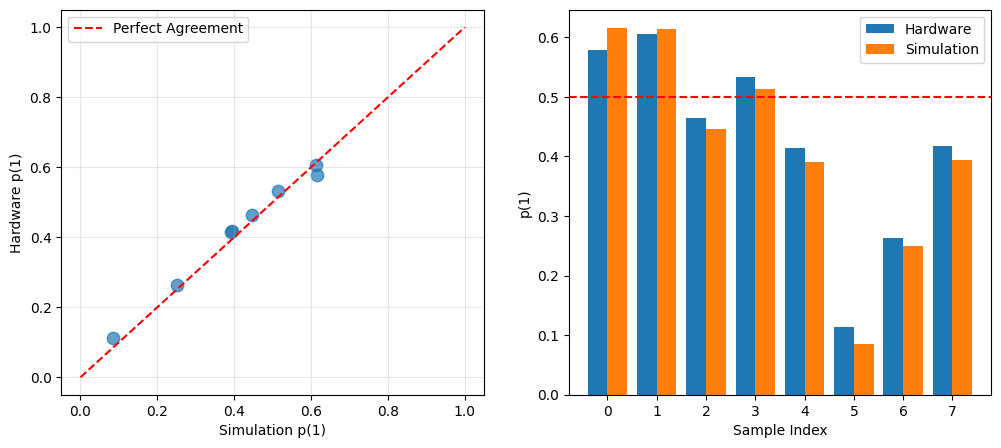

In [18]:
import matplotlib.pyplot as plt

def plot_hw_vs_sim(p1_hw, p1_sim, y_true, threshold=0.5):
    n = len(p1_hw)
    x = np.arange(n)

    fig, (ax1, ax2) = plt.subplots(1,2,figsize=(12,5))

    # Scatter
    ax1.scatter(p1_sim, p1_hw, s=80, alpha=0.7)
    ax1.plot([0,1],[0,1],'r--',label='Perfect Agreement')
    ax1.set_xlabel("Simulation p(1)"); ax1.set_ylabel("Hardware p(1)")
    ax1.legend(); ax1.grid(alpha=0.3)

    # Bar chart
    ax2.bar(x-0.2, p1_hw, 0.4, label="Hardware")
    ax2.bar(x+0.2, p1_sim, 0.4, label="Simulation")
    ax2.axhline(y=threshold, color="red", linestyle="--")
    ax2.set_xticks(x); ax2.set_xlabel("Sample Index"); ax2.set_ylabel("p(1)")
    ax2.legend()

    plt.show()

plot_hw_vs_sim(p1_hw, predictions_sim, Y_batch, threshold=0.5)


In [19]:
from scipy.stats import pearsonr

diffs = [abs(h-s) for h,s in zip(p1_hw, predictions_sim)]
correlation, _ = pearsonr(p1_hw, predictions_sim)

print("Noise Analysis")
print("="*40)
print(f"Correlation HW vs SIM: {correlation:.3f}")
print(f"Avg difference: {np.mean(diffs):.3f}")


Noise Analysis
Correlation HW vs SIM: 0.995
Avg difference: 0.021
